# End-to-end Multi-class Dog Breed Classification
This notebook builds an end-to-end multi-class image classifier using Tensorflow 2.0 and Tensorflow Hub.

# 1.Problem

Identifying the breed of a dog given an image of dog.
When I'm sitting at the cafe and I take a photo of a dog, I want to know what breed of dog it is.

# 2. Data

The data we're using from Kaggle's dog breed identification competition
https://www.kaggle.com/competitions/dog-breed-identification/data

# 3. Evaluation

The evaluation is a file with prediction probabilities for each dog breed of each test image.
https://www.kaggle.com/competitions/dog-breed-identification/overview/evaluation

# 4. Features

Some information about the data:
* We're dealing with images (unstructured data) so it's probably best we use deep learning/transfer learning.
* There are 120 breeds of dogs (this means there are 120 different classes).
* There are around 10,000 images in the training set (these images have labels) .
* There are around 10,000 images in the test set (these images have no labels, because we'll want to predict them).

In [ ]:
# Unzip the uploaded data into Google Drive
!unzip "drive/MyDrive/Colab Notebooks/Dog-vision/dog-breed-identification (1).zip" -d "drive/MyDrive/Colab Notebooks/Dog-vision/"

# Get our workspace ready
* Import TensorFlow 2.x
* Import TensorFlow Hub
* Make sure we're using a GPU


In [ ]:
# Import Tensorflow into Colab
import tensorflow as tf
import tensorflow_hub as hub
print("TF version:",tf.__version__)
print("TF Hub version:", hub.__version__)

# Check for GPU availability
print("GPU", "available (YESSSS!!!!!)" if tf.config.list_physical_devices ( "GPU") else "not available :(")

TF version: 2.19.0
TF Hub version: 0.16.1
GPU available (YESSSS!!!!!)


# Getting our data ready (tuning into Tensors)
With all machine learning models, our data has to be in numerical format. So that's what we'll be doing first. (numerical representations.)
Let's start by accesing our data and checking out the labels.

In [ ]:
# Checkout the labels of our data
import pandas as pd
labels_csv = pd.read_csv("drive/MyDrive/Colab Notebooks/Dog-vision/labels.csv")
print(labels_csv.describe())
print(labels_csv.head())

                                      id               breed
count                              10222               10222
unique                             10222                 120
top     fff43b07992508bc822f33d8ffd902ae  scottish_deerhound
freq                                   1                 126
                                 id             breed
0  000bec180eb18c7604dcecc8fe0dba07       boston_bull
1  001513dfcb2ffafc82cccf4d8bbaba97             dingo
2  001cdf01b096e06d78e9e5112d419397          pekinese
3  00214f311d5d2247d5dfe4fe24b2303d          bluetick
4  0021f9ceb3235effd7fcde7f7538ed62  golden_retriever


In [ ]:
labels_csv.head()

,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


<Axes: xlabel='breed'>

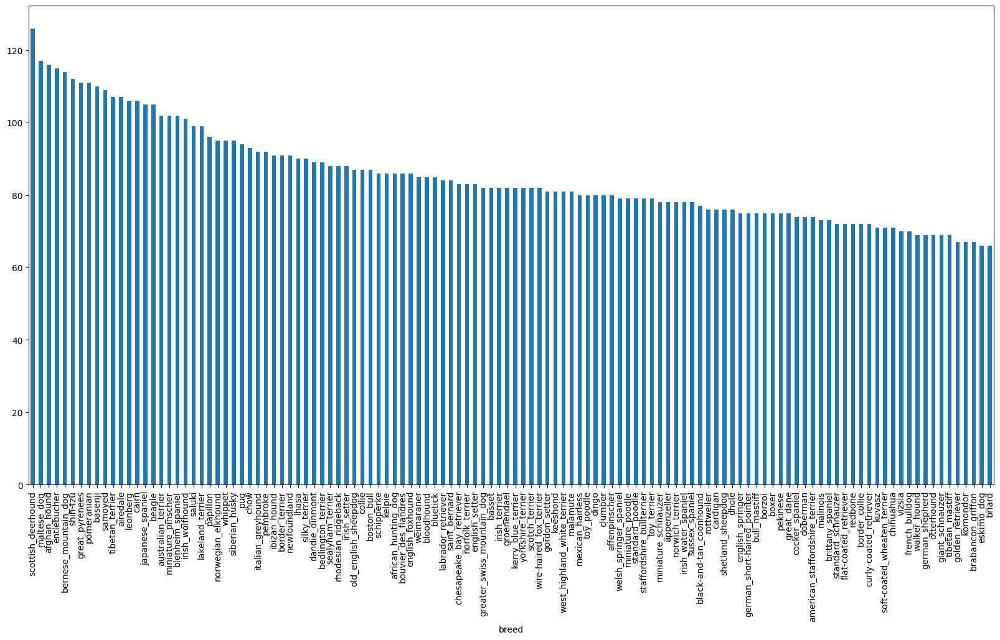

In [ ]:
# How many images are there of each breed?
labels_csv["breed"].value_counts().plot.bar(figsize=(20,10))

In [ ]:
# What's the median number of images per class?
labels_csv["breed"].value_counts().median()

82.0

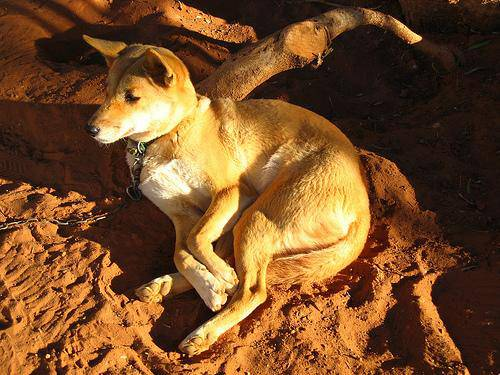

In [ ]:
# Let's view an image
from IPython.display import Image
Image("drive/MyDrive/Colab Notebooks/Dog-vision/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg")

# Getting images and their labels
Let's get a list of all our image file pathnames.

In [ ]:
labels_csv.head()

,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


In [ ]:
# Create pathnames from image ID's
filenames = ["drive/MyDrive/Colab Notebooks/Dog-vision/train/" + fname + ".jpg" for fname in labels_csv["id"]]

# Check the first 10
filenames[:10]

['drive/MyDrive/Colab Notebooks/Dog-vision/train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/001cdf01b096e06d78e9e5112d419397.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/00214f311d5d2247d5dfe4fe24b2303d.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/0021f9ceb3235effd7fcde7f7538ed62.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/002211c81b498ef88e1b40b9abf84e1d.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/00290d3e1fdd27226ba27a8ce248ce85.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/002a283a315af96eaea0e28e7163b21b.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/003df8b8a8b05244b1d920bb6cf451f9.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/0042188c895a2f14ef64a918ed9c7b64.jpg']

In [ ]:
# Check whether number of filenames matches number of actual image files
import os
if len(os.listdir("drive/MyDrive/Colab Notebooks/Dog-vision/train/")) == len(filenames):
  print("Filenames match actual amount of file!!! Proceed.")
else:
  print("Filenames do not match actual amount of files, change the target directory")

Filenames match actual amount of file!!! Proceed.


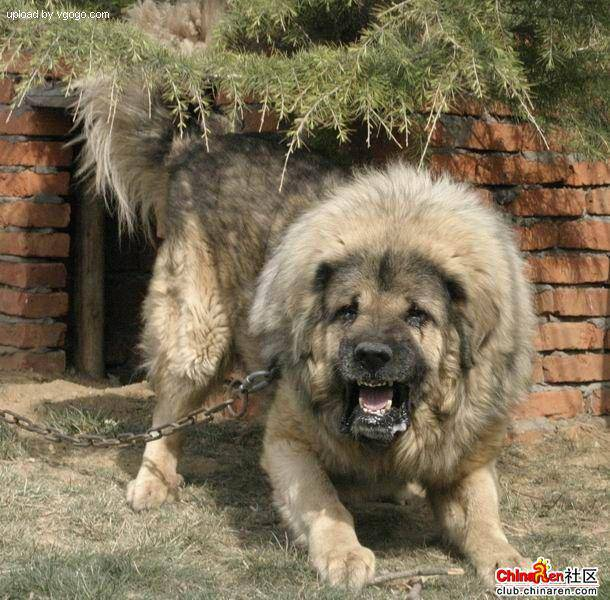

In [ ]:
# One more check
Image(filenames[9000])

In [ ]:
labels_csv["breed"][9000]

'tibetan_mastiff'

Since we've got our training image filepaths in a list, let's prepare our labels.

In [ ]:
import numpy as np
labels = labels_csv["breed"].to_numpy()
# Labels = np.array(labels) #does same thing as above
labels

array(['boston_bull', 'dingo', 'pekinese', ..., 'airedale',
       'miniature_pinscher', 'chesapeake_bay_retriever'], dtype=object)

In [ ]:
len(labels)

10222

In [ ]:
# See if number of labels matches the number of filenames
if len(labels) == len(filenames):
  print("Number of labels matches number of filenames!")
else:
  print("Number of labels does not match number of filenames, check data directoties!")

Number of labels matches number of filenames!


In [ ]:
# Find the unique label values
unique_breeds = np.unique(labels)
len(unique_breeds)

120

In [ ]:
# Turn a single label into an array of booleans
print(labels[0])
labels[0] == unique_breeds

boston_bull


array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False])

In [ ]:
# Turn every label into a boolean array
boolean_labels = [label == np.array(unique_breeds) for label in labels]
boolean_labels[:2]

[array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False,  True, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False]),
 array([False, False, False, False, False, Fal

In [ ]:
len(boolean_labels)

10222

In [ ]:
# Example: Tuning boolean array into integers
print(labels[0]) # original label
print(np.where(unique_breeds == labels[0])) # index where label occurs
print(boolean_labels[0].argmax()) # index where label occurs in boolean array
print(boolean_labels[0].astype(int)) # there will be a 1 where the sample label occurs

boston_bull
(array([19]),)
19
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0]


In [ ]:
print(labels[2])
print(boolean_labels[2].astype(int))

pekinese
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0]


In [ ]:
filenames[:10]

['drive/MyDrive/Colab Notebooks/Dog-vision/train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/001cdf01b096e06d78e9e5112d419397.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/00214f311d5d2247d5dfe4fe24b2303d.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/0021f9ceb3235effd7fcde7f7538ed62.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/002211c81b498ef88e1b40b9abf84e1d.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/00290d3e1fdd27226ba27a8ce248ce85.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/002a283a315af96eaea0e28e7163b21b.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/003df8b8a8b05244b1d920bb6cf451f9.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/train/0042188c895a2f14ef64a918ed9c7b64.jpg']

# Creating our own validation set
Since the dataset from kaggle doesn't come with a validation set, we're going to create our own.

In [ ]:
# Setup X & y variables
X = filenames
y = boolean_labels

In [ ]:
len(filenames)

10222

We're going to start off experimenting with about 1000 images and increases as needed.

In [ ]:
# set number of images to use for experimenting
NUM_IMAGES = 1000 #@param {type:"slider",min:1000,max:1

In [ ]:
# let's split our data into train and validation sets
from sklearn.model_selection import train_test_split

# Split them into training and validation of total size NUM_IMAGES
X_train, X_val, y_train, y_val = train_test_split(X[:NUM_IMAGES],
                                                  y[:NUM_IMAGES],
                                                  test_size=0.2,
                                                  random_state=42)

len(X_train), len(y_train), len(X_val), len(y_val)

(800, 800, 200, 200)

In [ ]:
# Let's have a geez at the training data
X_train[:5], y_train[:5]

(['drive/MyDrive/Colab Notebooks/Dog-vision/train/00bee065dcec471f26394855c5c2f3de.jpg',
  'drive/MyDrive/Colab Notebooks/Dog-vision/train/0d2f9e12a2611d911d91a339074c8154.jpg',
  'drive/MyDrive/Colab Notebooks/Dog-vision/train/1108e48ce3e2d7d7fb527ae6e40ab486.jpg',
  'drive/MyDrive/Colab Notebooks/Dog-vision/train/0dc3196b4213a2733d7f4bdcd41699d3.jpg',
  'drive/MyDrive/Colab Notebooks/Dog-vision/train/146fbfac6b5b1f0de83a5d0c1b473377.jpg'],
 [array([False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False,  True,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False,

# Preprocessing images (turning images into Tensors)

to preprocessing our data image into Tensors we're going to write a function which does a few things:
1. Take an `image` filepath as input
2. Use TensorFlow to read the file and save it to a variable, image
3. Turn our `image` (a jpg) into Tensors
4. Resize the `image` to be a shape of (224, 224)
5. Return the modified `image`
Before we do, let's see what importing an image looks like.

In [ ]:
# Convert image to NumPy array
from matplotlib.pyplot import imread
image = imread(filenames[42])
image.shape

(257, 350, 3)

In [ ]:
# Turn image into a tensor
tf.constant(image)[:2]

<tf.Tensor: shape=(2, 350, 3), dtype=uint8, numpy=
array([[[ 89, 137,  89],
        [ 76, 124,  76],
        [ 63, 111,  61],
        ...,
        [ 77, 133,  86],
        [ 76, 134,  86],
        [ 76, 134,  86]],

       [[ 72, 119,  75],
        [ 67, 114,  68],
        [ 63, 110,  64],
        ...,
        [ 75, 131,  84],
        [ 74, 132,  84],
        [ 74, 132,  84]]], dtype=uint8)>

# Now we've seen what an imahe looks like as a Tensor, let's make a function to preprocess them.

1. Take an `image` filepath as input
2. Use TensorFlow to read the file and save it to a variable, `image`
3. Turn our `image` (a jpg) into Tensors
4. Normalize our image (convert color channel values from  0-255 to 0-1)
5. Resize the `image` to be a shape of (224, 224)
6. Return the modified `image`


In [ ]:
# Define image size
IMG_SIZE = 224

# Create a function for preprocessing images
def process_image(image_path):
  """
  Takes an image file path and turns it into a Tensor.
  """

  # Read in an image file
  image = tf.io.read_file(image_path)
  # Turn the jpeg image into numerical Tensor with 3 colour channels (Red,Green,Blue)
  image = tf.image.decode_jpeg(image, channels=3)
  # Convert the colour channel values from 0-255 to 0-1 values
  image = tf.image.convert_image_dtype(image, tf.float32)
  # Resize the image to our desired size (244,244)
  image = tf.image.resize(image, size=[IMG_SIZE,IMG_SIZE])

  return image

## Turning our data into batches
Why turn our data into batches?
Let's say you're trying to process 10,000 images in one go... they all might not fit into memory.
So that's why we do about 32 (this is the batch size) images at a time (you can manually adjust the batch size if need be) •
In order to use TensorFlow effectively, we need our data in the form of Tensor tuples which look like this:
`(image, label)`.

In [ ]:
#Create a simple function to return a tuple (image, label)
def get_image_label (image_path, label):
  """
  Takes an image file path name and the associated label, processes the image and reutrns a typle of (image, label).
  """

  image = process_image(image_path)
  return image, label

In [ ]:
## Demo of the abovel
(process_image (X[42]), tf.constant(y[42]))

(<tf.Tensor: shape=(224, 224, 3), dtype=float32, numpy=
 array([[[0.3264178 , 0.5222886 , 0.3232816 ],
         [0.2537167 , 0.44366494, 0.24117757],
         [0.25699762, 0.4467087 , 0.23893751],
         ...,
         [0.29325107, 0.5189916 , 0.3215547 ],
         [0.29721776, 0.52466875, 0.33030328],
         [0.2948505 , 0.5223015 , 0.33406618]],
 
        [[0.25903144, 0.4537807 , 0.27294815],
         [0.24375686, 0.4407019 , 0.2554778 ],
         [0.2838985 , 0.47213382, 0.28298813],
         ...,
         [0.2785345 , 0.5027992 , 0.31004712],
         [0.28428748, 0.5108719 , 0.32523635],
         [0.28821915, 0.5148036 , 0.32916805]],
 
        [[0.20941195, 0.40692952, 0.25792548],
         [0.24045378, 0.43900946, 0.2868911 ],
         [0.29001117, 0.47937486, 0.32247734],
         ...,
         [0.26074055, 0.48414773, 0.30125174],
         [0.27101526, 0.49454468, 0.32096273],
         [0.27939945, 0.5029289 , 0.32934693]],
 
        ...,
 
        [[0.00634795, 0.03442048

Now we've got a way to turn data into tuples of Tensors in the form: `(image, label)`, let's make a function to turn all of our data (X & y) into batches

In [ ]:
# Define the batch size, 32 is a good start
BATCH_SIZE = 32

# Create a function to turn data into batches
def create_data_batches(X, y=None, batch_size=BATCH_SIZE, valid_data=False, test_data=False):
  """
  Creates batches of data out of image (X) and label (y) pairs.
  Shuffles the data if it's training data but doesn't shuffle it if it's validation data.
  Also accepts test data as input (no labels).
  """

  # If the data is a test dataset, we probably don't have labels
  if test_data:
    print("Creating test data batches...")
    data = tf.data.Dataset.from_tensor_slices((tf.constant(X))) # only filepaths (no labels)
    data_batch = data.map(process_image).batch(BATCH_SIZE)
    return data_batch

  # If the data is a valid dataset, we don't need to shuffle it
  elif valid_data:
    print("Creating validation data batches...")
    data = tf.data.Dataset.from_tensor_slices((tf.constant(X), #filepaths
                                               tf.constant(y))) #labels
    data_batch = data.map(get_image_label).batch(BATCH_SIZE)
    return data_batch

  else:
    # If the data is a training dataset, we shuffle it
    print("Creating training data batches...")
    # Turn filepaths and labels into Tensors
    data = tf.data.Dataset.from_tensor_slices((tf.constant(X), #filepaths
                                               tf.constant(y))) #labels
    # Shuffling pathnames and labels before mapping image processor function is faster than shuffle
    data = data.shuffle(buffer_size=len(X))

    # Create (image,label) tuples (this also turns the image path into a preprocessed image)
    data = data.map(get_image_label)

    # Turn the training data into batches
    data_batch = data.batch(BATCH_SIZE)
    return data_batch

In [ ]:
# Create training and validation data batches
train_data = create_data_batches(X_train, y_train)
val_data = create_data_batches(X_val, y_val, valid_data=True)

Creating training data batches...
Creating validation data batches...


In [ ]:
# Check out the different attributes of our data batches
train_data.element_spec, val_data.element_spec

((TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)),
 (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)))

# Visualizing Data batches
Our data is now in batches, however, these can be a little hard to understnad/comprehend, let's visualize them

In [ ]:
import matplotlib.pyplot as plt

# Create a function for viewing images in a data batch
def show_25_images(image,labels):
  """
  Displays a plot of images and their labels from a data batch
  """
  # Setup the figure
  plt.figure(figsize=(10,10))
  # Loop through 25 (for displaying 25 images)
  for i in range(25):
    # Create subplots (5 rows, 5 columns)
    ax = plt.subplot(5,5,i+1)
    # Display an image
    plt.imshow(image[i])
    # Add the image label
    plt.title(unique_breeds[labels[i].argmax()])
    # Turn the grid lines off
   # plt.axis("off")


In [ ]:
train_images, train_labels = next(train_data.as_numpy_iterator())
train_images, train_labels

(array([[[[6.53076544e-02, 6.13860823e-02, 4.56998050e-02],
          [6.25942200e-02, 5.86726516e-02, 4.29863743e-02],
          [5.65802529e-02, 5.26586846e-02, 3.69724073e-02],
          ...,
          [5.50595298e-02, 5.11379614e-02, 3.54516841e-02],
          [5.50595298e-02, 5.11379614e-02, 3.54516841e-02],
          [5.50595298e-02, 5.11379614e-02, 3.54516841e-02]],
 
         [[6.22724108e-02, 5.83508424e-02, 4.26645651e-02],
          [5.89698032e-02, 5.50482348e-02, 3.93619575e-02],
          [5.91052473e-02, 5.51836789e-02, 3.94974016e-02],
          ...,
          [5.97689115e-02, 5.58473431e-02, 4.01610658e-02],
          [5.97689115e-02, 5.58473431e-02, 4.01610658e-02],
          [5.97689115e-02, 5.58473431e-02, 4.01610658e-02]],
 
         [[5.80357164e-02, 5.41141480e-02, 3.84278707e-02],
          [5.87901212e-02, 5.48685528e-02, 3.91822755e-02],
          [6.11607172e-02, 5.72391488e-02, 4.15528715e-02],
          ...,
          [6.66666701e-02, 6.27451017e-02, 4.7058

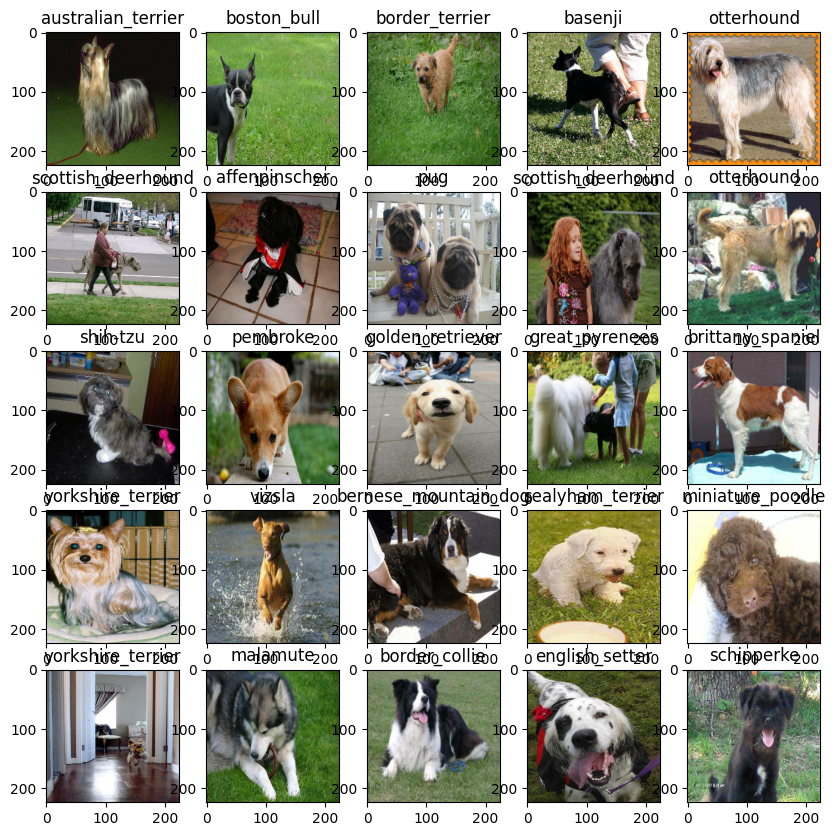

In [ ]:
# Now let's visualize the data in a training batch
show_25_images(train_images, train_labels)

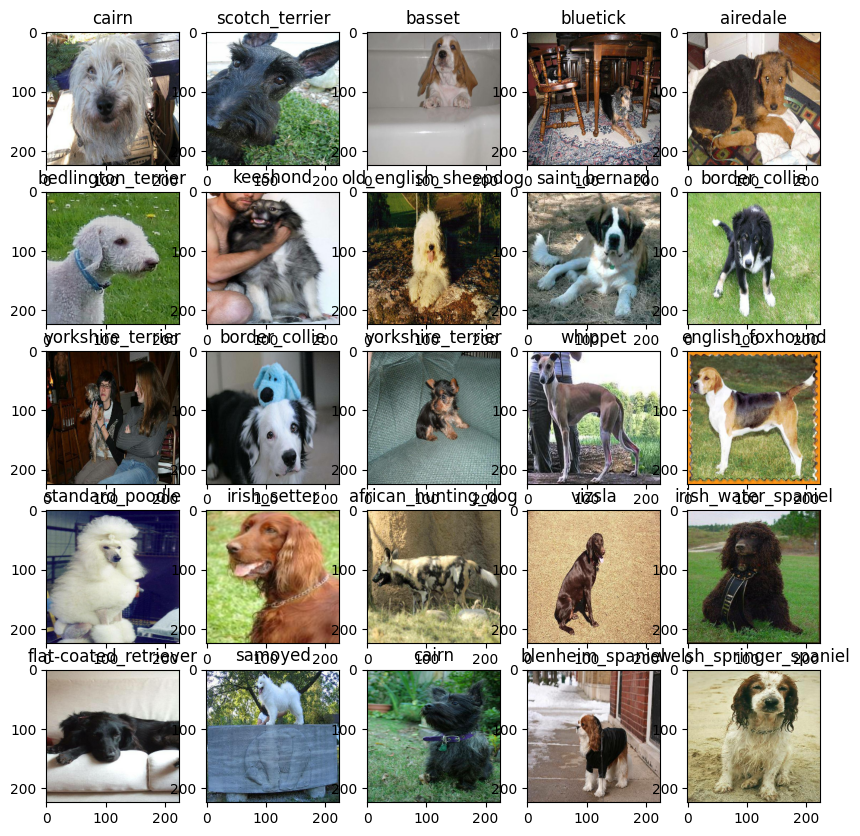

In [ ]:
# Now let's visualize our validation set
val_images, val_labels = next(val_data.as_numpy_iterator())
show_25_images(val_images, val_labels)

# Building a model
Before we build a model, there are few things we need to define:
* The input shape (our images shape, in the form of Tensors) to our model.
* The output shape (image labels, in the form of Tensors) of our model.
* The URL of the model we want use.

In [ ]:
IMG_SIZE


224

In [ ]:
# Setup input shape to the model
INPUT_SHAPE = [None, IMG_SIZE, IMG_SIZE,3] #batch, height, width, colour channels

# Setup output shape of our model
OUTPUT_SHAPE = len(unique_breeds)

# Setup model URL from TensorFlow Hub
MODEL_URL = "https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4"

Now we've got our inputs, outputs and model ready to go. Let's put them together into a Keras deep learning model!
Knowing this, let's create a function which:
* Takes the input shape, output shape and the model we ve chosen as parameters.
* Defines the layers in a Keras model in sequential fashion (do this first, then this, then that).
* Compiles the model (says it should be evaluated and improved).
* Builds the model (tells the model the input shape it'll be getting).
* Returns the model.

All of these steps can be found here: https://www.tensorflow.org/guide/keras/overview

In [ ]:
# Create a function which builds a keras model
def create_model(input_shape = INPUT_SHAPE, output_shape=OUTPUT_SHAPE, model_url=MODEL_URL):
  print("Building model with:", MODEL_URL)

  hubs_layer = hub.KerasLayer(MODEL_URL)

    # Setup the model layers

  model = tf.keras.Sequential([

    tf.keras.layers.Lambda(lambda x: hubs_layer(x)), # Layer 1 (input layer)

    tf.keras.layers.Dense(units=OUTPUT_SHAPE,

                          activation="softmax") # Layer 2 (output layer)

    ])

  # compile the model
  model.compile(
      loss=tf.keras.losses.CategoricalCrossentropy(),
      optimizer=tf.keras.optimizers.Adam(),
      metrics=["accuracy"]
  )

  # Build the model
  model.build(INPUT_SHAPE)

  return model

In [ ]:
model = create_model()
model.summary()

Building model with: https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 1001)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │       120,240 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,240 (469.69 KB)

 Trainable params: 120,240 (469.69 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
outputs = np.ones(shape=(1,1,1280))
outputs

array([[[1., 1., 1., ..., 1., 1., 1.]]])

#Creating callbacks
Callbacks are helper functions a model can use during training to do such things as save its progress, check its progress or stop training early if a model stops improving.
We'll create two callbacks, one for TensorBoard which helps track our models progress and another for early stopping which prevents our model from training for too long.
TensorBoard Callback
To setup a TensorBoard callback, we need to do 3 things:
1. Load the TensorBoard notebook extension
2. Create a TensorBoard callback which is able to save logs to a directory and pass it to our model's fit () function.
3. Visualize our models training logs with the stensorboard magic function (we'll do this after model training).

In [ ]:
# Load TensorBoard notebook extension
%load_ext tensorboard

In [ ]:
import datetime
# Create a function to build a TensorBoard callback
def create_tensorboard_callback():
  # Create a log directory for storing TensorBoard logs
  logdir = os.path.join("drive/My Drive/Dog vision/logs",
                      # Make it so the logs get tracked whenever we run an experiment)
                      datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))

  return tf.keras.callbacks.TensorBoard(logdir)

#Early Stopping Callback
Early stopping helps stop our model from overfitting by stopping training if a certain evaluation metric stops improving.
https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping

In [ ]:
# Create early stopping callback
early_stopping = tf.keras.callbacks.EarlyStopping (monitor="val_accuracy",
patience=3)

# Training a model(on subset of data)
Our first model is only going to train on 1000 images, to make sure everything is working.

In [ ]:
NUM_EPOCHS = 100 #@param {type:"slider",min:10,max:100,step:10}

In [ ]:
# Check to make sure er're still running on a GPU
print("GPU", "avaliable (YESSS!!!!!!)" if tf.config.list_physical_devices("GPU") else "not available :(")

GPU avaliable (YESSS!!!!!!)


Let's create a function which trains a model

* Create a model using `create_tensorboard_callback()`
* Setup a TensorBoard callback using `create_tensorboard_callback()`
* Call the `fit()` function on our model passing it the training data, validation data, number of epochs to train for (NUM_EPOCHS) and the callbacks we'd like to use
* Return the model

In [ ]:
# Build a function to train and return a trained model
def train_model():
  """
  Trains a given model and returns the trained version.
  """

  # Create a model
  model = create_model()

  # Create new TensorBoard session everytime we train a model
  tensorboard = create_tensorboard_callback()

  # Fit the model ti the data passing it the callbacks we created
  model.fit(x=train_data,
            epochs = NUM_EPOCHS,
            validation_data = val_data,
            validation_freq=1,
            callbacks=[tensorboard,early_stopping])

  # Return the filled model
  return model

In [ ]:
# Fit the model to the data
model = train_model()

Building model with: https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4
Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 254s 9s/step - accuracy: 0.0471 - loss: 5.0848 - val_accuracy: 0.2700 - val_loss: 3.2651
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 205ms/step - accuracy: 0.6092 - loss: 1.9178 - val_accuracy: 0.4500 - val_loss: 2.1220
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 214ms/step - accuracy: 0.9211 - loss: 0.6651 - val_accuracy: 0.5900 - val_loss: 1.6701
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 164ms/step - accuracy: 0.9890 - loss: 0.2674 - val_accuracy: 0.6250 - val_loss: 1.4716
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 161ms/step - accuracy: 0.9976 - loss: 0.1584 - val_accuracy: 0.6250 - val_loss: 1.3901
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 216ms/step - accuracy: 0.9993 - loss: 0.1047 - val_accuracy: 0.6400 - val_loss: 1.3577
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 9s 162ms/step - accuracy: 1.0000 - loss: 0.0813 - val_accuracy: 0.6400 - val_loss: 1.3254
Epoch

**Question:** It looks like our model is overfitting because it's performing far better on the training dataset than the validation dataset, what are some ways to prevent model overfitting in deep learning neural networks?

**Note:** Overfitting to begin with is a good thing! It means our model is learning

# Checking the TensorBoard logs

The TensorBoard magic function (%tensorboard) will access the logs directory we created earlier and visualize its contents.

In [ ]:
%tensorboard --logdir "drive/MyDrive/Dog vision/logs"

<IPython.core.display.Javascript object>

## Making and evaluating predictions using a trained model

In [ ]:
# Make predictions on the validation data (not used to train on)
predictions = model.predict(val_data, verbose=1) # set verbosity to see how long is left
predictions

7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 711ms/step


array([[2.0102602e-03, 2.7163616e-05, 8.6047687e-04, ..., 2.6306431e-04,
        2.4229570e-05, 7.9169422e-03],
       [2.5412978e-03, 5.0243345e-04, 3.4651929e-03, ..., 2.1530772e-04,
        4.2684018e-04, 9.9166398e-05],
       [4.5834436e-06, 8.1260914e-05, 4.1690682e-06, ..., 7.2941431e-05,
        7.0190523e-05, 1.6058513e-04],
       ...,
       [3.3705073e-05, 5.4701121e-04, 7.3226501e-04, ..., 2.1776081e-05,
        2.5615795e-04, 8.8244960e-05],
       [1.0205243e-02, 1.6725468e-04, 3.8843343e-04, ..., 8.8656240e-04,
        7.9834419e-05, 2.4493815e-02],
       [1.1286192e-04, 3.2214530e-06, 8.4687135e-04, ..., 8.5751736e-04,
        5.9599513e-03, 8.1596401e-05]], dtype=float32)

In [ ]:
np.sum(predictions[0])

np.float32(0.99999994)

In [ ]:
# First prediction
index = 42
print(predictions[index])
print(f"Max value (probability of prediction): {np.max(predictions[index])}")
print(f"Sum: {np.sum(predictions[index])}")
print(f"Max index: {np.argmax(predictions[index])}")
print(f"Predicted label: {unique_breeds[np.argmax(predictions[index])]}")

[5.16237851e-05 7.37870359e-05 9.49773894e-05 2.10634462e-05
 1.43099471e-03 2.11225561e-04 1.64149722e-04 2.05429853e-03
 9.06805880e-03 6.43386245e-02 3.59876904e-05 7.28659052e-06
 1.16550647e-04 3.64890764e-03 5.28051576e-04 3.10117216e-03
 4.64764926e-05 1.51360320e-04 6.70283553e-05 9.60871403e-04
 4.00729623e-05 3.36185010e-04 5.11963517e-05 7.13881382e-05
 8.21480434e-03 2.13425901e-05 4.67038954e-05 1.01546240e-04
 2.91594712e-04 8.31221223e-06 7.04766062e-05 5.03826377e-05
 3.53124669e-05 1.74104298e-05 8.70385702e-06 6.34994285e-05
 6.61634695e-05 2.62609858e-04 1.76731555e-05 1.34766474e-01
 5.14655512e-05 1.71809625e-05 4.33571870e-03 4.03603235e-06
 1.10639085e-04 8.87800197e-05 1.88238802e-04 1.04650483e-03
 1.10530609e-05 2.61001929e-04 6.54669566e-05 7.98613764e-05
 7.02161400e-04 4.38613258e-03 1.51147196e-05 9.68836248e-05
 5.99498380e-05 8.23307782e-05 1.25881721e-04 2.92058485e-05
 5.73646230e-06 5.25433454e-04 1.60606851e-05 7.47389568e-05
 3.74203519e-05 5.993131

In [ ]:
unique_breeds[39]

'english_foxhound'

Having the the above functionality is great but we want to be able to do it at scale.
And it would be even better if we could see the image the prediction is being made on!

**Note:** Prediction probabilities are also known as confidence levels.

In [ ]:
#Turn prediction probabilities into their respective label (easier to understand)
def get_pred_label(prediction_probabilities) :
  """
Turns an array of prediction probabilities into a label.
  """
  return unique_breeds[np.argmax(prediction_probabilities)]
#Get a predicted label based on an array of prediction probabilities
pred_label = get_pred_label(predictions [9])
pred_label

'collie'

Now since our validation data is still in a batch dataset, we'll have to unbatchify it to make predictions on the validation images and then compare those predictions to the validation labels (truth labels).

In [ ]:
val_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

In [ ]:
# Create a function to unbatch a batch dataset
def unbatchify(data):
  """
  Takes a batched dataset of (image,label) Tensors and returns separate arrays
  of images and labels.
  """
  images = []
  labels = []
  # Loop through unbatched data
  for image, label in data.unbatch().as_numpy_iterator():
    images.append(image)
    labels.append(unique_breeds[np.argmax(label)])
  return images,labels

 #Unbatchify the validation data
val_images, val_labels = unbatchify(val_data)
val_images[0],val_labels[0]

(array([[[0.29599646, 0.43284872, 0.3056691 ],
         [0.26635826, 0.32996926, 0.22846507],
         [0.31428418, 0.27701408, 0.22934894],
         ...,
         [0.77614343, 0.82320225, 0.8101595 ],
         [0.81291157, 0.8285351 , 0.8406944 ],
         [0.8209297 , 0.8263737 , 0.8423668 ]],
 
        [[0.2344871 , 0.31603682, 0.19543913],
         [0.3414841 , 0.36560842, 0.27241898],
         [0.45016077, 0.40117094, 0.33964607],
         ...,
         [0.7663987 , 0.8134138 , 0.81350833],
         [0.7304248 , 0.75012016, 0.76590735],
         [0.74518913, 0.76002574, 0.7830809 ]],
 
        [[0.30157745, 0.3082587 , 0.21018331],
         [0.2905954 , 0.27066195, 0.18401104],
         [0.4138316 , 0.36170745, 0.2964005 ],
         ...,
         [0.79871625, 0.8418535 , 0.8606443 ],
         [0.7957738 , 0.82859945, 0.8605655 ],
         [0.75181633, 0.77904975, 0.8155256 ]],
 
        ...,
 
        [[0.9746779 , 0.9878955 , 0.9342279 ],
         [0.99153054, 0.99772066, 0.94278

In [ ]:
get_pred_label(val_images[0])

'vizsla'

Now we've got ways to get :
* Prediction labels
* Validation labels (truth labels)
* Validation images

Let's make some function to make these all a bit more visualize

We'll create a function which:
* Takes an array of prediction probabilities, an array of truth labels and array of  images and integers.

* Convert the prediction probabilities to a predictied label.

* Plot the predictied label, its predicted probability, the truth label and the target image oon a single plot.

In [ ]:
def plot_pred(prediction_probabilities, labels, images, n=1):
  """
  View the prediction, ground truth label and image for sample n.
  """
  pred_prob, true_label, image = prediction_probabilities[n], labels[n], images[n]
  # Get the pred label
  pred_label = get_pred_label(pred_prob)

  # Plot image & remove ticks
  plt.imshow(image)
  plt.xticks([])
  plt.yticks([])

  # Change plot title to be predicted, probability of prediction and truth label
  plt.title("{} {2.0f}% {}".format(pred_label,np.max(pred_prob)*100,true_label))



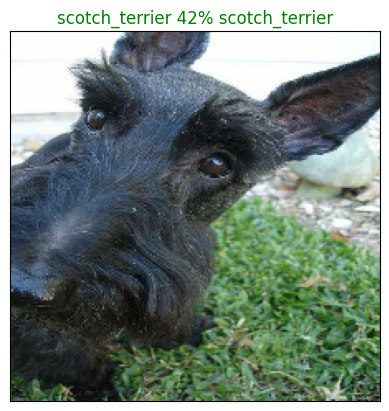

In [ ]:
def plot_pred(prediction_probabilities, labels, images, n=1):
  """
  View the prediction, ground truth label and image for sample n.
  """
  pred_prob, true_label, image = prediction_probabilities[n], labels[n], images[n]
  # Get the pred label
  pred_label = get_pred_label(pred_prob)

  # Plot image & remove ticks
  plt.imshow(image)
  plt.xticks([])
  plt.yticks([])

  # Change the colour of the title depending on if the prediction is right or wrong
  if pred_label == true_label:
    color = "green"
  else:
    color = "red"

  # Change plot title to be predicted, probability of prediction and truth label
  plt.title("{} {:2.0f}% {}".format(pred_label, np.max(pred_prob)*100, true_label),color=color )

plot_pred(prediction_probabilities=predictions, labels=val_labels, images=val_images)

Now we've got one function to visualize our models top prediction, let's make another to view our models top 10 predictions.
This function will:
* Take an input of prediction probabilities array and a ground truth array and an integer
* Find the prediction using get pred_label ()
* Find the top 10:
  * Prediction probabilities indexes
  * Prediction probabilities values
  * Prediction labels
* Plot the top 10 prediction probability values and labels, coloring the true label green

In [ ]:
def plot_pred_conf(prediction_probabilities, labels, n=1):
  """
  Plot the top 10 highest prediction confidences along with the truth label for sample n.
  """
  pred_prob, true_label = prediction_probabilities[n], labels[n]

  # Get the predicted label
  pred_label = get_pred_label(pred_prob)

  # Find the top 10 prediction confidence indexes
  top_10_pred_indexes = pred_prob.argsort()[-10:][::-1]
  # Find the top 10 prediction confidence values
  top_10_pred_values = pred_prob[top_10_pred_indexes]
  # Find the top 10 prediction labels
  top_10_pred_labels = unique_breeds[top_10_pred_indexes]

  # Setup plot
  top_plot = plt.bar(np.arange(len(top_10_pred_labels)),
                     top_10_pred_values,
                     color="grey")
  plt.xticks(np.arange(len(top_10_pred_labels)),
             labels=top_10_pred_labels,
             rotation="vertical")

  # Change color of true label
  if np.isin(true_label, top_10_pred_labels):
    top_plot[np.argmax(top_10_pred_labels == true_label)].set_color("green")
  else:
    pass


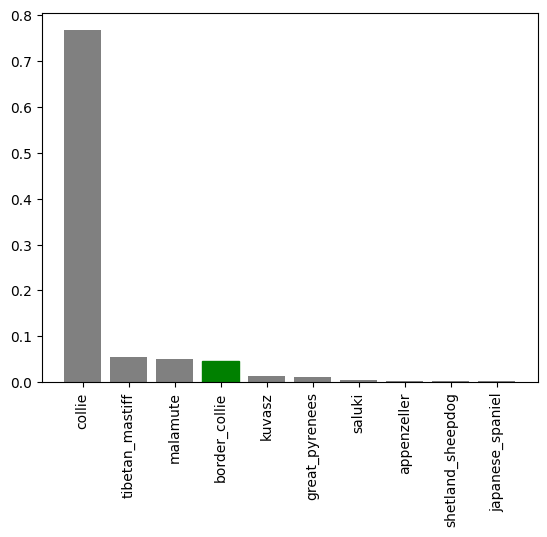

In [ ]:
plot_pred_conf(prediction_probabilities=predictions, labels=val_labels,n=9)

Now we've got some function to help us visualize our predictions and evaluate our model, let's check out a few

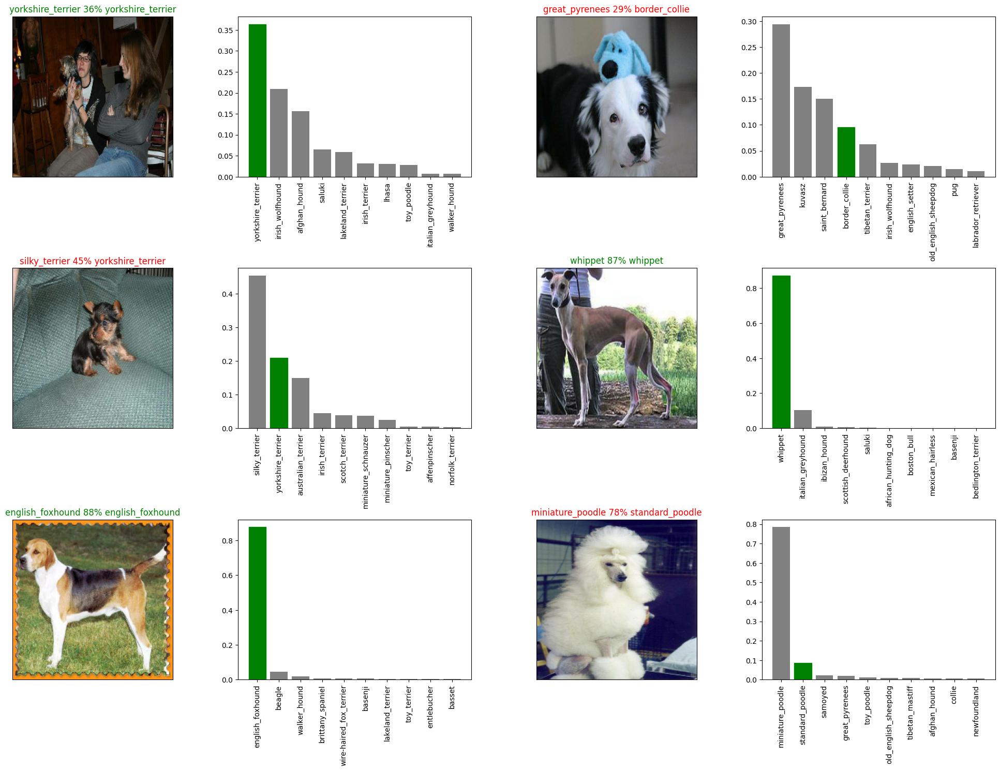

In [ ]:
# Let's check out a few predictions and their different values
i_multiplier = 10
num_rows = 3
num_cols = 2
num_images = num_rows * num_cols
plt.figure(figsize=(10*num_cols,5*num_rows))
for i in range(num_images):
  plt.subplot(num_rows,2*num_cols,2*i+1)
  plot_pred(prediction_probabilities=predictions, labels=val_labels, images=val_images, n=i+i_multiplier)
  plt.subplot(num_rows,2*num_cols,2*i+2)
  plot_pred_conf(prediction_probabilities=predictions, labels=val_labels, n=i+i_multiplier)
plt.tight_layout(h_pad=1.0)
plt.show()

**Challenge:**
How would you create a confusion matrix with our models predictions and true labels?



## Saving and loading a trained model

In [ ]:
# Create a function to save a model
def save_model(model,suffix=None):
  """
  Saves a given model in a models directory and appends a suffix (str)
  for separating models.
  """
  # Create a model directory pathname with current time
  modeldir = os.path.join("drive/MyDrive/Dog vision/ models",
                          datetime.datetime.now().strftime("%Y%m%d-%H%M%s"))
  model_path = modeldir + "-" + suffix + ".keras" # Change to .keras for native Keras format
  print(f"Saving model to: {model_path}...")
  model.save(model_path) # Actually save the model
  return model_path

In [ ]:
# Create a function to load a trained model
def load_model(model_path):
  """
  Loads a saved model from a specified path.
  """
  print(f"Loading saved model from: {model_path}")
  return tf.keras.models.load_model(model_path,
                                    custom_objects={"KerasLayer":hub.KerasLayer})
  return model

Now we've got functions to save and load a trained model, let's make sure they work!

In [ ]:
# Save our model trained on 1000 images
#save_model(model, suffix="1000-images-mobilenetv2-Adam")

In [ ]:
#Load a trained model
#loaded_1000_image_model = load_model('drive/MyDrive/ Dog vision/ models/20251211-08231765441424-1000-images-mobilenetv2-Adam.h5')

In [ ]:
#Evaluate the loaded model
#loaded_1000_image_model.evaluate(val_data)

## Training a big dog model ( on the full data)

In [ ]:
len(X),len(y)

(10222, 10222)

In [ ]:
# Create a data batch with the full data set
full_data = create_data_batches(X,y)

Creating training data batches...


In [ ]:
full_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

In [ ]:
# Create a model for full model
full_model = create_model()

Building model with: https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4


In [ ]:
# Create full model callbacks
full_model_tensorboard = create_tensorboard_callback()
# No validation set when training on all the data, so we can't monitor validation accuracy
full_model_early_stopping = tf.keras.callbacks.EarlyStopping(monitor="accuracy",patience=3)

**Note:** Running the cell below will take a little while (maybe up to 30 minutes for the first epoch) because the GPU we're using in the runtime has to load all of the images into memory

In [ ]:
#Fit the full model to the full data
full_model.fit(x=full_data,epochs=NUM_EPOCHS,callbacks=[full_model_tensorboard,full_model_early_stopping])

Epoch 1/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 67s 181ms/step - accuracy: 0.4885 - loss: 2.4010
Epoch 2/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 47s 146ms/step - accuracy: 0.8949 - loss: 0.3715
Epoch 3/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 46s 143ms/step - accuracy: 0.9419 - loss: 0.2285
Epoch 4/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 82s 143ms/step - accuracy: 0.9697 - loss: 0.1417
Epoch 5/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 46s 145ms/step - accuracy: 0.9839 - loss: 0.0990
Epoch 6/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 81s 142ms/step - accuracy: 0.9889 - loss: 0.0725
Epoch 7/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 46s 145ms/step - accuracy: 0.9916 - loss: 0.0554
Epoch 8/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 45s 140ms/step - accuracy: 0.9964 - loss: 0.0420
Epoch 9/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 46s 142ms/step - accuracy: 0.9972 - loss: 0.0352
Epoch 10/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 45s 142ms/step - accuracy: 0.9977 - loss: 0.0286
Epoch 11/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 46s 143ms/step - accuracy: 0.9983 - loss: 0.0246
Epoch 12

Making predictions on the test dataset
Since our model has been trained on images in the form of Tensor batches, to make predictions on the test data, we'll have to get it into the same format.
Luckily we created create _data_batches () earlier which can take a list of filenames as input and conver them into Tensor batches.
To make predictions on the test data, we'll:
* Get the test image filenames.
* Convert the filenames into test data batches using create_date_batches () and setting the test_data parameter to True (since the test data doesn't have labels).
* Make a predictions array by passing the test batches to the predict () method called on our model.

In [ ]:
# Load test images filenames
test_path = "drive/MyDrive/Colab Notebooks/Dog-vision/test"
test_filenames = [os.path.join(test_path, fname) for fname in os.listdir(test_path)]
test_filenames[:10]

['drive/MyDrive/Colab Notebooks/Dog-vision/test/e0f2620cb1ebf648b986c8a09dbd3664.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/test/e21d378710d164f126e7d0b380dc7a1a.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/test/e09f4ff3f7acee994812650a2fc7edef.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/test/e0f9b92adbba451d296678f466732969.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/test/e504cbd0094fc72312087587795be597.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/test/dcab2d03a686ab3f31d1bc3e5700f6d1.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/test/de327414ced20d4e6f786a68bff82e10.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/test/e71fde4ddc4c1adf9b4cf397e3904f74.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/test/e5fa615e36dc3b2b3f554aa5097a6ece.jpg',
 'drive/MyDrive/Colab Notebooks/Dog-vision/test/e5560686ee44dc59dbb99d6ef4ea54d8.jpg']

In [ ]:
# Create test data batch
test_data = create_data_batches(test_filenames,test_data=True)

Creating test data batches...


In [ ]:
test_data

<_BatchDataset element_spec=TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)>

**Note:** Calling predict() on our full model and passing it the test data batch will take a long time to run

In [ ]:
# Make predictions on test data batch using the full model
test_predictions = full_model.predict(test_data,verbose=1)

324/324 ━━━━━━━━━━━━━━━━━━━━ 293s 848ms/step


In [ ]:
# Save predictions (NumPy array) to csv file (for access later)
np.savetxt("drive/MyDrive/Dog vision/ test_predictions.csv",test_predictions,delimiter=",")

In [ ]:
# Load predictions (NumPy array) from csv file
test_predictions = np.loadtxt("drive/MyDrive/Dog vision/ test_predictions.csv",delimiter=",")

## Making predictions on custom images
To make predictions on custom images, we'll:
* Get the filepaths of our own images.
* Turn the filepaths into data batches using
create_data _batches () • And since our custom images won't have labels, we set the test _data parameter to True
* Pass the custom image data batch to our model's predict()
- method.
* Convert the prediction output probabilities to predictions labels.
* Compare the predicted labels to the custom images.

In [ ]:
# Get custom image filepaths
custom_path = "drive/MyDrive/Dog vision/my-dog-photos"
custom_image_paths = [os.path.join(custom_path, fname) for fname in os.listdir(custom_path)]
custom_image_paths

['drive/MyDrive/Dog vision/my-dog-photos/images (1).jpg',
 'drive/MyDrive/Dog vision/my-dog-photos/images (2).jpg',
 'drive/MyDrive/Dog vision/my-dog-photos/images.jpg',
 'drive/MyDrive/Dog vision/my-dog-photos/4554685686.jpg']

In [ ]:
custom_image_paths

['drive/MyDrive/Dog vision/my-dog-photos/images (1).jpg',
 'drive/MyDrive/Dog vision/my-dog-photos/images (2).jpg',
 'drive/MyDrive/Dog vision/my-dog-photos/images.jpg',
 'drive/MyDrive/Dog vision/my-dog-photos/4554685686.jpg']

In [ ]:
# Turn custom images into batches datasets
custom_data = create_data_batches(custom_image_paths,test_data=True)
custom_data

Creating test data batches...


<_BatchDataset element_spec=TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)>

In [ ]:
# Make predictions on the custom data
custom_preds = full_model.predict(custom_data)

1/1 ━━━━━━━━━━━━━━━━━━━━ 17s 17s/step


In [ ]:
custom_preds.shape

(4, 120)

In [ ]:
# Get custom image prediction labels
custom_pred_labels = [get_pred_label(custom_preds[i]) for i in range(len(custom_preds))]
custom_pred_labels
#

['german_shepherd',
 'french_bulldog',
 'black-and-tan_coonhound',
 'golden_retriever']

In [ ]:
# Get custom images (our unbatchify() function won't work since there aren't labels...)
custom_images = []
for images in custom_data.unbatch().as_numpy_iterator():
  custom_images.append(images)
custom_images = custom_images[:len(custom_pred_labels)]

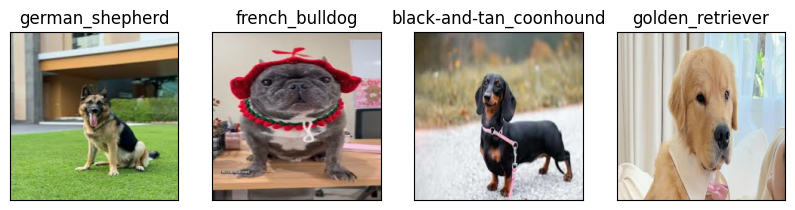

In [ ]:
# Check custom image predictions
plt.figure(figsize=(10,10))
for i, (image, label) in enumerate(zip(custom_images, custom_pred_labels)):
  plt.subplot(1,4,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.title(custom_pred_labels[i])
  plt.imshow(image)
#